# Importer les bibliothèques

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

print("Toutes les bibliothèques sont prêtes !")

Toutes les bibliothèques sont prêtes !


In [3]:
# Charger le dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Classes :", np.unique(y))
print("Valeurs des pixels :", X.min(), "à", X.max())

Dimensions de X : (1797, 64)
Dimensions de y : (1797,)
Classes : [0 1 2 3 4 5 6 7 8 9]
Valeurs des pixels : 0.0 à 16.0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test :", X_test.shape)

Taille de X_train : (1437, 64)
Taille de X_test : (360, 64)


In [5]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        max_iter=500,
        random_state=42,
        early_stopping=True
    ))
])

print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('mlp',
                 MLPClassifier(early_stopping=True, max_iter=500,
                               random_state=42))])


In [6]:
param_grid = {
    "mlp__hidden_layer_sizes": [
        (50,),
        (100,),
        (50, 30),
        (100, 50)
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__solver": ["adam", "sgd"],
    "mlp__alpha": [0.0001, 0.001]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(grid_search.best_params_)

print("\nMeilleure accuracy moyenne en validation croisée :")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Meilleurs paramètres :
{'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (100, 50), 'mlp__solver': 'adam'}

Meilleure accuracy moyenne en validation croisée :
0.9548


In [7]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy sur le test : {accuracy:.4f}")
print(f"Accuracy en pourcentage : {accuracy * 100:.2f}%")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

Accuracy sur le test : 0.9667
Accuracy en pourcentage : 96.67%

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.88      0.97      0.92        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.95      1.00      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      0.94      0.97        36
           7       0.97      1.00      0.99        36
           8       0.94      0.83      0.88        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



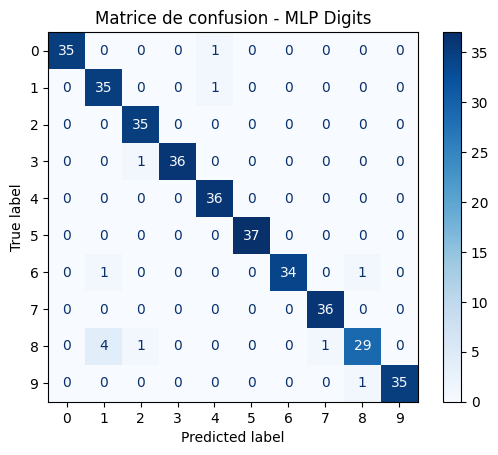

In [8]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digits.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - MLP Digits")
plt.show()

In [9]:
results = pd.DataFrame(grid_search.cv_results_)

columns = [
    "param_mlp__hidden_layer_sizes",
    "param_mlp__activation",
    "param_mlp__solver",
    "param_mlp__alpha",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

top_models = results[columns].sort_values(
    by="rank_test_score"
).head(10)

display(top_models)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__solver,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
6,"(100, 50)",relu,adam,0.0001,0.954767,0.002604,1
14,"(100, 50)",relu,adam,0.0010,0.947112,0.012907,2
30,"(100, 50)",tanh,adam,0.0010,0.944328,0.008747,3
22,"(100, 50)",tanh,adam,0.0001,0.944328,0.008747,3
18,"(100,)",tanh,adam,0.0001,0.943633,0.006146,5
26,"(100,)",tanh,adam,0.0010,0.943633,0.006146,5
12,"(50, 30)",relu,adam,0.0010,0.937370,0.003409,7
4,"(50, 30)",relu,adam,0.0001,0.937370,0.003409,7
28,"(50, 30)",tanh,adam,0.0010,0.929019,0.019360,9
20,"(50, 30)",tanh,adam,0.0001,0.929019,0.019360,9


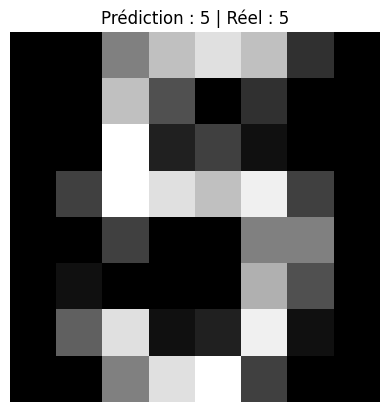

Probabilité estimée pour chaque chiffre :
0 : 0.07%
1 : 0.00%
2 : 0.00%
3 : 0.04%
4 : 0.11%
5 : 76.52%
6 : 0.02%
7 : 0.00%
8 : 0.01%
9 : 23.22%


In [10]:
index = 0

image = X_test[index].reshape(8, 8)
prediction = best_model.predict(X_test[index].reshape(1, -1))[0]
probabilities = best_model.predict_proba(
    X_test[index].reshape(1, -1)
)[0]

plt.imshow(image, cmap="gray")
plt.title(f"Prédiction : {prediction} | Réel : {y_test[index]}")
plt.axis("off")
plt.show()

print("Probabilité estimée pour chaque chiffre :")
for chiffre, proba in enumerate(probabilities):
    print(f"{chiffre} : {proba:.2%}")

In [11]:
joblib.dump(best_model, "mlp_digits_pipeline.joblib")

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [12]:
from google.colab import files

files.download("mlp_digits_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
%%writefile app.py
import streamlit as st
import numpy as np
import matplotlib.pyplot as plt
import joblib

st.set_page_config(page_title="MLP Digits", page_icon="🔢")

@st.cache_resource
def load_model():
    return joblib.load("mlp_digits_pipeline.joblib")

model = load_model()

st.title("Reconnaissance de chiffres manuscrits")
st.write("Dessinez un chiffre sur la grille 8 × 8.")

pixels = []

for i in range(8):
    cols = st.columns(8)
    row = []
    for j in range(8):
        value = cols[j].selectbox(
            f"Pixel {i},{j}",
            options=[0, 4, 8, 12, 16],
            index=0,
            key=f"pixel_{i}_{j}",
            label_visibility="collapsed"
        )
        row.append(value)
    pixels.extend(row)

if st.button("Prédire le chiffre"):
    image = np.array(pixels, dtype=float).reshape(1, 64)

    prediction = model.predict(image)[0]
    probabilities = model.predict_proba(image)[0]

    st.success(f"Chiffre prédit : {prediction}")

    fig, ax = plt.subplots()
    ax.imshow(image.reshape(8, 8), cmap="gray", vmin=0, vmax=16)
    ax.axis("off")
    st.pyplot(fig)

    st.subheader("Probabilités estimées")
    st.bar_chart({
        str(i): float(probabilities[i])
        for i in range(10)
    })

Writing app.py


In [14]:
%%writefile requirements.txt
streamlit
scikit-learn
numpy
matplotlib
joblib

Writing requirements.txt


In [16]:
from google.colab import files

files.download("app.py")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>